# Electricity | Classificação do preço da eletricidade em NSW (queda/alta)

**Disciplina:** Introdução ao Aprendizado de Máquina

**Integrantes:** Estevan Hernandes (CP3031187), Marcus Vinicius (CP3031721) e Pedro Henrique (CP3029352)

**Objetivo:** Classificar se o preço da energia em New South Wales está abaixo (`down`) ou acima (`up`) da média móvel recente. A classe positiva das classificações será **`down` (queda)**.

## 1. Base e preparação

### 1.1 Origem e descrição

**Fonte:** OpenML - [Electricity, dataset 151](https://www.openml.org/d/151). Licença registrada como *Public*. Referência: Harries, M. (1999). *Splice-2 Comparative Evaluation: Electricity Pricing*. Technical Report, University of New South Wales.

**O que cada linha representa:** um período de **30 minutos** do mercado de eletricidade australiano, com dados de New South Wales (NSW) e Victoria (VIC), de **maio de 1996 a dezembro de 1998**.

**Divisão fornecida pelo professor:**

| Conjunto | Registros | Período |
| --- | ---: | --- |
| Treino | 36.240 | parte inicial da sequência |
| Teste | 9.072 | parte final da sequência |

**Atributos:**

| Variável | Tipo | Descrição |
| --- | --- | --- |
| `date_normalized` | numérica (temporal) | Data normalizada entre 0 e 1 |
| `day` | categórica | Dia da semana (`day_1` a `day_7`) |
| `period_index` | inteira (temporal, cíclica) | Período de meia hora no dia (1 a 48) |
| `nsw_price_normalized` | numérica contínua | Preço normalizado em NSW |
| `nsw_demand_normalized` | numérica contínua | Demanda normalizada em NSW |
| `vic_price_normalized` | numérica contínua | Preço normalizado em VIC |
| `vic_demand_normalized` | numérica contínua | Demanda normalizada em VIC |
| `transfer_normalized` | numérica contínua | Transferência programada entre os estados |
| `nsw_price_class` | **alvo** (categórica binária) | `down` ou `up`: preço de NSW abaixo ou acima da média móvel recente |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

train = pd.read_csv("../data/electricity_train.csv")
test  = pd.read_csv("../data/electricity_test.csv")

TARGET   = "nsw_price_class"
NUM_COLS = ["nsw_price_normalized", "nsw_demand_normalized",
            "vic_price_normalized", "vic_demand_normalized", "transfer_normalized"]
VIC_COLS = ["vic_price_normalized", "vic_demand_normalized", "transfer_normalized"]

In [3]:
print("Treino:", train.shape)
print("Teste: ", test.shape)

display(train.head())
train.info()

# Checagens de qualidade
cols_norm = ["date_normalized"] + NUM_COLS
print("\nNulos - treino:", train.isna().sum().sum(), "| teste:", test.isna().sum().sum())
print("Linhas duplicadas:", train.duplicated().sum())
print("Valores de day:", sorted(train["day"].unique()))
print("period_index:", train["period_index"].min(), "a", train["period_index"].max())
print("Classes do alvo:", train[TARGET].unique())
print("Valores fora de [0, 1]:", ((train[cols_norm] < 0) | (train[cols_norm] > 1)).sum().sum())

Treino: (36240, 9)
Teste:  (9072, 9)


,date_normalized,day,period_index,nsw_price_normalized,nsw_demand_normalized,vic_price_normalized,vic_demand_normalized,transfer_normalized,nsw_price_class
0,0.0,day_2,1,0.056443,0.439155,0.003467,0.422915,0.414912,up
1,0.0,day_2,2,0.051699,0.415055,0.003467,0.422915,0.414912,up
2,0.0,day_2,3,0.051489,0.385004,0.003467,0.422915,0.414912,up
3,0.0,day_2,4,0.045485,0.314639,0.003467,0.422915,0.414912,up
4,0.0,day_2,5,0.042482,0.251116,0.003467,0.422915,0.414912,down


<class 'pandas.DataFrame'>
RangeIndex: 36240 entries, 0 to 36239
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date_normalized        36240 non-null  float64
 1   day                    36240 non-null  str    
 2   period_index           36240 non-null  int64  
 3   nsw_price_normalized   36240 non-null  float64
 4   nsw_demand_normalized  36240 non-null  float64
 5   vic_price_normalized   36240 non-null  float64
 6   vic_demand_normalized  36240 non-null  float64
 7   transfer_normalized    36240 non-null  float64
 8   nsw_price_class        36240 non-null  str    
dtypes: float64(6), int64(1), str(2)
memory usage: 2.5 MB

Nulos - treino: 0 | teste: 0
Linhas duplicadas: 0
Valores de day: ['day_1', 'day_2', 'day_3', 'day_4', 'day_5', 'day_6', 'day_7']
period_index: 1 a 48
Classes do alvo: <StringArray>
['up', 'down']
Length: 2, dtype: str
Valores fora de [0, 1]: 0


In [4]:
# Alvo binário: down (queda) = 1, que é a classe de interesse; up (alta) = 0
mapa_alvo = {"up": 0, "down": 1}

y_train = train[TARGET].map(mapa_alvo)
y_test  = test[TARGET].map(mapa_alvo)

print("Contagem no treino:")
print(train[TARGET].value_counts())
print("\nProporção no treino:")
print(train[TARGET].value_counts(normalize=True).round(3))

Contagem no treino:
nsw_price_class
down    21097
up      15143
Name: count, dtype: int64

Proporção no treino:
nsw_price_class
down    0.582
up      0.418
Name: proportion, dtype: float64


Victoria preenchida: 17424 linhas (48.1% do treino), da linha 0 à 17423
Linhas assim no teste: 0


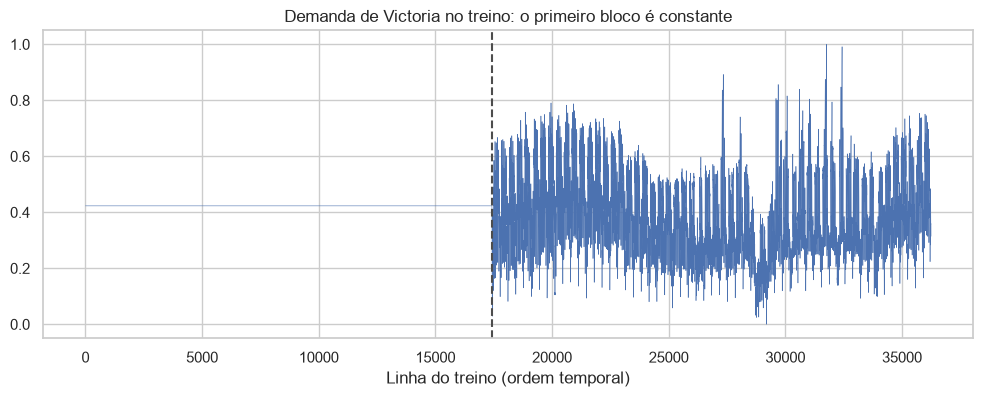

In [5]:
# Valores fixos que aparecem repetidos nas colunas de Victoria
valores_preenchidos = train[VIC_COLS].mode().iloc[0]

# True nas linhas em que as 3 colunas de Victoria têm o valor preenchido ao mesmo tempo
linha_preenchida = (train[VIC_COLS] == valores_preenchidos).all(axis=1)
posicoes_preenchidas = np.where(linha_preenchida)[0]
ultima_linha_preenchida = posicoes_preenchidas.max()

print(f"Victoria preenchida: {linha_preenchida.sum()} linhas ({linha_preenchida.mean():.1%} do treino), "
      f"da linha {posicoes_preenchidas.min()} à {ultima_linha_preenchida}")
print("Linhas assim no teste:", (test[VIC_COLS] == valores_preenchidos).all(axis=1).sum())

# Evidência visual
ax = train["vic_demand_normalized"].plot(figsize=(12, 4), linewidth=0.4,
        title="Demanda de Victoria no treino: o primeiro bloco é constante")
ax.axvline(ultima_linha_preenchida, color="0.3", linestyle="--")
ax.set_xlabel("Linha do treino (ordem temporal)")
plt.show()

### Faltantes disfarçados nas colunas de Victoria

A verificação de nulos (`isna()`) não encontrou nenhum valor ausente. Porém, ao analisar as colunas de Victoria (`vic_price`, `vic_demand` e `transfer`), observou-se que:

- **17.424 linhas (48,1% do treino)** apresentam exatamente os mesmos valores nas três colunas.
- Essas linhas formam um **bloco contínuo no início da base** (linhas 0 a 17.423), o que corresponde a cerca de **363 dias**, praticamente o primeiro ano do período (maio/1996 a maio/1997).
- O conjunto de **teste não possui** nenhuma linha com esse padrão.

Em um mercado de energia real, preço e demanda variam a cada meia-hora, então valores idênticos durante um ano inteiro não são plausíveis. Conclui-se que **os dados de Victoria não estavam disponíveis nesse período** e foram preenchidos com um valor fixo. Trata-se de um **valor faltante disfarçado**: existe um número na célula, por isso o `isna()` não o detecta, mas ele não representa uma medição real.

**Impactos:**
1. Quase metade do treino tem 3 das 5 variáveis numéricas sem informação real.
2. Como o teste não tem esse bloco, um modelo que aprenda padrões a partir dele pode não generalizar para o período avaliado.
3. O acúmulo de valores idênticos distorce estatísticas como quartis e, consequentemente, a detecção de outliers (analisada mais adiante).

In [6]:
# 1 = Victoria sem dado real (bloco preenchido); 0 = dado real
for base in (train, test):
    base["vic_sem_dado"] = (base[VIC_COLS] == valores_preenchidos).all(axis=1).astype(int)

print("vic_sem_dado no treino:", train["vic_sem_dado"].value_counts().to_dict())
print("vic_sem_dado no teste: ", test["vic_sem_dado"].value_counts().to_dict())

taxa_queda_por_grupo = y_train.groupby(train["vic_sem_dado"]).mean().round(3)
print("\nTaxa de queda por grupo (treino):")
print(taxa_queda_por_grupo)

vic_sem_dado no treino: {0: 18816, 1: 17424}
vic_sem_dado no teste:  {0: 9072}

Taxa de queda por grupo (treino):
vic_sem_dado
0    0.600
1    0.563
Name: nsw_price_class, dtype: float64


### Decisão: tratamento dos faltantes disfarçados

| Opção | Vantagem | Desvantagem |
|---|---|---|
| Remover as 17.424 linhas | Treino só com dados reais | Perde 48% do treino, incluindo as informações de NSW, que são reais nesse período |
| Imputar (média ou interpolação) | Mantém todas as linhas | Seria inventar um ano inteiro de dados de Victoria; não há valores vizinhos para interpolar |
| Remover as colunas de Victoria | Simples | Descarta informação real do restante do treino e de todo o teste |
| **Manter + variável indicadora** | **Preserva os dados de NSW e permite ao modelo distinguir os dois períodos** | A indicadora é sempre 0 no teste |

**Decisão adotada:** manter as linhas e criar a variável `vic_sem_dado` (1 = Victoria sem dado real, 0 = dado real). Com ela, o modelo pode aprender que, quando `vic_sem_dado = 1`, os valores de Victoria não carregam informação. No teste, como todas as linhas têm dados reais, o modelo usa o comportamento aprendido no período completo.

Como verificação, na etapa de modelagem será feito um **experimento comparativo**: treinar com a base inteira (com a indicadora) e treinar apenas com o período completo (`vic_sem_dado = 0`), avaliando qual estratégia gera melhores resultados na validação.

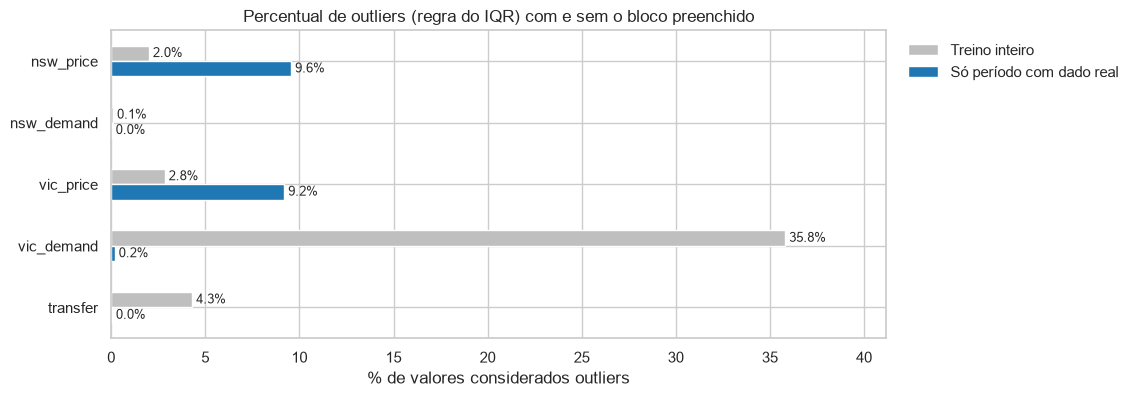

In [7]:
def percentual_outliers(dados):
    """% de valores fora do intervalo [Q1 - 1,5·IQR, Q3 + 1,5·IQR] em cada coluna."""
    q1 = dados.quantile(0.25)
    q3 = dados.quantile(0.75)
    iqr = q3 - q1
    fora_do_intervalo = (dados < q1 - 1.5 * iqr) | (dados > q3 + 1.5 * iqr)
    return fora_do_intervalo.mean() * 100

periodo_completo = train[train["vic_sem_dado"] == 0]

comparacao_outliers = pd.DataFrame({
    "Treino inteiro":            percentual_outliers(train[NUM_COLS]),
    "Só período com dado real":  percentual_outliers(periodo_completo[NUM_COLS]),
}).rename(index=lambda coluna: coluna.replace("_normalized", ""))

ax = comparacao_outliers.plot.barh(figsize=(10, 4), color=["0.75", "tab:blue"])
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f%%", padding=3, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, comparacao_outliers.values.max() * 1.15)
ax.set_title("Percentual de outliers (regra do IQR) com e sem o bloco preenchido")
ax.set_xlabel("% de valores considerados outliers")
ax.set_ylabel("")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.show()

### Outliers

A detecção de outliers foi feita pela **regra do IQR**: um valor é considerado outlier quando fica abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR, isto é, muito afastado da faixa onde está a metade central dos dados.

**Efeito do bloco preenchido:** no treino inteiro, cerca de **36%** dos valores de `vic_demand` foram marcados como outliers. Considerando apenas o período com dados reais de Victoria, esse percentual cai para **0,2%**. Isso acontece porque metade dos valores está concentrada em um único número (o valor de preenchimento), o que estreita artificialmente a faixa entre Q1 e Q3 e faz variações normais parecerem anormais. Portanto, a análise de outliers deve considerar o período com dados reais.

**Outliers reais:** mesmo no período com dados reais, cerca de **9%** dos preços de NSW e de Victoria ficam fora da faixa, quase sempre acima dela. Esses valores correspondem a **picos de preço**, comuns em mercados de energia quando a demanda está alta ou a oferta está baixa. Não são erros de medição.

**Decisão adotada:** **manter os outliers**, pelos seguintes motivos:
1. São valores reais do mercado, e não erros de coleta.
2. Removê-los apagaria justamente os momentos mais extremos do fenômeno que se quer prever.

Trechos com data adiantada (contados pela queda de volta) — treino: 3 | teste: 1


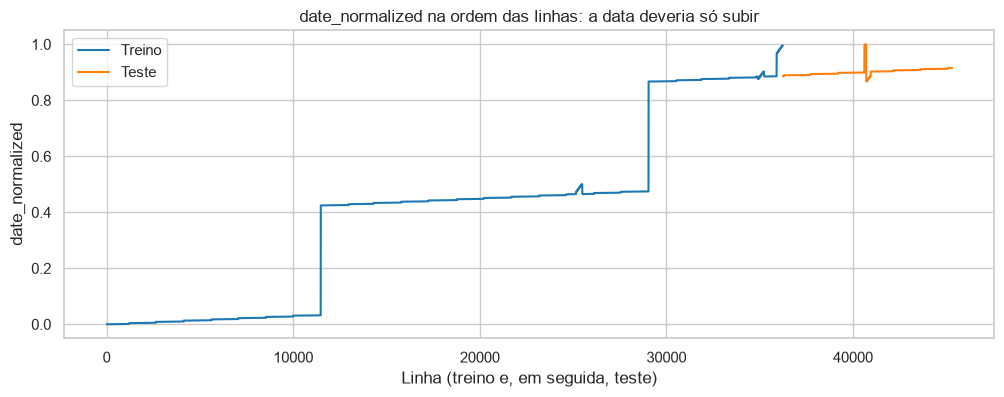

In [8]:
# Cada linha é meia hora depois da anterior, então a data deveria só subir
saltos_treino = (train["date_normalized"].diff() < 0).sum()
saltos_teste  = (test["date_normalized"].diff() < 0).sum()
print("Trechos com data adiantada (contados pela queda de volta) — treino:", saltos_treino, "| teste:", saltos_teste)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(range(len(train)), train["date_normalized"], color="tab:blue", label="Treino")
ax.plot(range(len(train), len(train) + len(test)), test["date_normalized"],
        color="tab:orange", label="Teste")
ax.set_title("date_normalized na ordem das linhas: a data deveria só subir")
ax.set_xlabel("Linha (treino e, em seguida, teste)")
ax.set_ylabel("date_normalized")
ax.legend()
plt.show()

### Inconsistências em `date_normalized`

Como cada linha representa meia hora depois da anterior, a data deveria subir de forma lisa e contínua. O gráfico mostra dois problemas:

- **Picos de data adiantada:** em alguns trechos de cerca de uma semana, a data pula para cima e depois volta para a sequência normal, tanto no treino quanto no teste. A última semana do treino é um desses trechos, por isso o treino termina com uma data maior que a do início do teste.
- **Escala não uniforme:** a data sobe em pequenos degraus e dá dois saltos enormes, que coincidem com as viradas de ano. Ou seja, a distância entre dois valores não representa a distância real no tempo.

Enquanto isso, `day` e `period_index` seguem a sequência normal. Portanto, a **ordem das linhas está correta** e o problema está só na coluna de data.

**Decisões:**
- A **ordem das linhas** é usada como ordem temporal (na validação e na criação de lags).
- `date_normalized` **não entra nos modelos**, porque não é confiável e representaria uma tendência do período de treino que não se repete no teste.
- O efeito do tempo sobre o preço entra por `day` (dia da semana) e `period_index` (horário).

### Resumo da Etapa 1: qualidade dos dados

| Verificação | O que foi encontrado | Decisão |
|---|---|---|
| Valores nulos | Nenhum, no treino e no teste | Nada a tratar |
| Linhas duplicadas | Nenhuma | Nada a tratar |
| Faixa dos valores | Todas as variáveis normalizadas estão entre 0 e 1 | Nada a tratar |
| Faltantes disfarçados (Victoria) | Em 48,1% do treino (o primeiro ano da base), as 3 colunas de Victoria têm sempre os mesmos valores fixos, colocados no lugar dos dados que faltavam. Nenhum caso no teste | Manter as linhas e criar o indicador `vic_sem_dado`; testar também o treino só com o período com dado real |
| Outliers (regra do IQR) | No treino inteiro, ~36% da demanda de Victoria parecia outlier, mas era efeito dos valores fixos usados para preencher o primeiro ano. Considerando só o período com dado real, isso cai para ~0,2%. Os outliers que sobram (~9% nos preços) são picos reais de preço | Manter, pois são valores reais e importantes para o problema |
| `date_normalized` | A data não cresce de forma uniforme (dá saltos nas viradas de ano) e tem trechos de cerca de uma semana com data adiantada | Usar a ordem das linhas como tempo; não usar a data como variável |
| Classes do alvo | ~58% `down` / ~42% `up` | Sem balanceamento; avaliar com F1 e PR-AUC da classe `down` |

## Etapa 2: Análise Exploratória (EDA)

A análise usa **apenas o treino**, para que nenhuma informação do teste influencie as decisões. Nas perguntas que envolvem as colunas de Victoria, é usado só o período com dado real (`vic_sem_dado = 0`).

**Perguntas:**
1. Como o preço de NSW se distribui?
2. O preço e a demanda de NSW são diferentes quando o preço cai ou sobe? *(relacional)*
3. A chance de queda muda ao longo do dia? *(relacional)*
4. A chance de queda muda entre os dias da semana? *(relacional)*
5. Como as variáveis numéricas se relacionam entre si e com o alvo? *(relacional)*
6. A classe tende a se repetir de um período para o seguinte? *(relacional)*
7. O alvo pode ser explicado pelo preço em relação às últimas 24 horas? *(relacional)*
8. A proporção de quedas muda ao longo do tempo?

### Pergunta 1: como o preço de NSW se distribui?

count    36240.000
mean         0.056
std          0.037
min          0.000
25%          0.034
50%          0.047
75%          0.071
99%          0.153
max          1.000
Name: nsw_price_normalized, dtype: float64


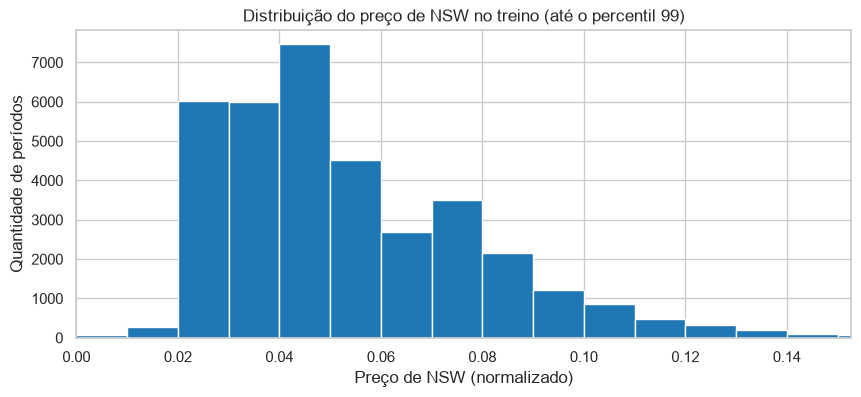

In [9]:
preco_nsw = train["nsw_price_normalized"]
print(preco_nsw.describe(percentiles=[0.25, 0.5, 0.75, 0.99]).round(3))

ax = preco_nsw.plot.hist(bins=100, figsize=(10, 4), color="tab:blue")
ax.set_xlim(0, preco_nsw.quantile(0.99))
ax.set_title("Distribuição do preço de NSW no treino (até o percentil 99)")
ax.set_xlabel("Preço de NSW (normalizado)")
ax.set_ylabel("Quantidade de períodos")
plt.show()

**Resposta:** o preço é fortemente concentrado em valores baixos: metade dos períodos tem preço até ~0,047 e 99% ficam abaixo de ~0,15, enquanto o máximo chega a 1,0. A distribuição tem uma cauda longa à direita, formada por picos de preço raros e muito altos (os outliers mantidos na Etapa 1).

**Implicação:** a média (~0,056) é puxada para cima pelos picos, então a mediana descreve melhor o preço típico. Para os modelos sensíveis à escala, a padronização acontece dentro do Pipeline.

### Pergunta 2: o preço e a demanda de NSW são diferentes quando o preço cai ou sobe?

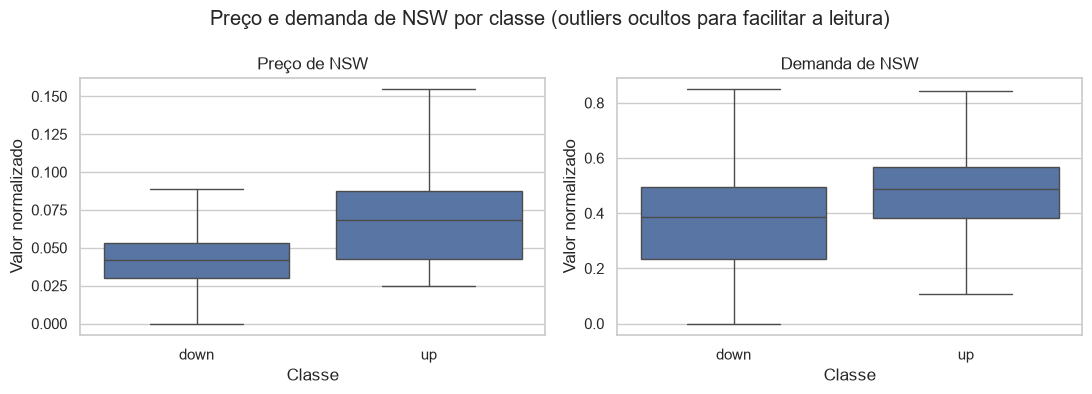

Mediana por classe:
                 nsw_price_normalized  nsw_demand_normalized
nsw_price_class                                             
down                            0.042                  0.387
up                              0.069                  0.487


In [10]:
variaveis_nsw = {"nsw_price_normalized": "Preço de NSW",
                 "nsw_demand_normalized": "Demanda de NSW"}

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for ax, (coluna, nome) in zip(eixos, variaveis_nsw.items()):
    sns.boxplot(x=train[TARGET], y=train[coluna], order=["down", "up"],
                showfliers=False, ax=ax)
    ax.set_title(nome)
    ax.set_xlabel("Classe")
    ax.set_ylabel("Valor normalizado")
fig.suptitle("Preço e demanda de NSW por classe (outliers ocultos para facilitar a leitura)")
plt.tight_layout()
plt.show()

print("Mediana por classe:")
print(train.groupby(TARGET)[list(variaveis_nsw)].median().round(3))

**Resposta:** sim. Nos períodos `down` (preço de NSW abaixo da média das últimas 24 horas), o preço e a demanda de NSW tendem a ser menores: a mediana do preço é 0,042 contra 0,069 nos períodos `up`, e a da demanda é 0,387 contra 0,487. Faz sentido, porque com menos consumo a energia tende a ficar mais barata.

Porém, as caixas se sobrepõem bastante: por exemplo, 25% dos períodos `down` têm preço acima de 0,053, valor maior que o de muitos períodos `up`. Ou seja, nenhuma das duas variáveis separa as classes sozinha, e os modelos vão precisar combinar várias informações.

### Pergunta 3: a chance de down muda ao longo do dia?

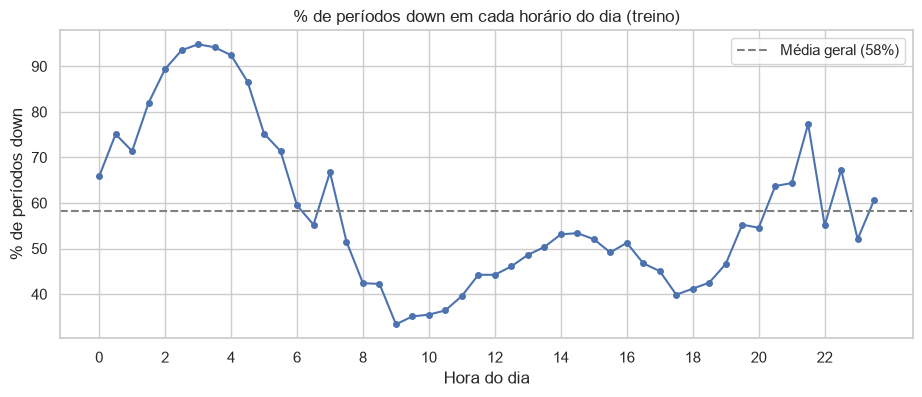

Maior % down: 95% (período 7)
Menor % down: 33% (período 19)


In [11]:
taxa_down_por_periodo = y_train.groupby(train["period_index"]).mean()
hora_do_dia = (taxa_down_por_periodo.index - 1) / 2      # período 1 = 00:00 ... período 48 = 23:30

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hora_do_dia, taxa_down_por_periodo * 100, marker="o", markersize=4)
ax.axhline(y_train.mean() * 100, color="0.5", linestyle="--",
           label=f"Média geral ({y_train.mean():.0%})")
ax.set_xticks(range(0, 24, 2))
ax.set_title("% de períodos down em cada horário do dia (treino)")
ax.set_xlabel("Hora do dia")
ax.set_ylabel("% de períodos down")
ax.legend()
plt.show()

print(f"Maior % down: {taxa_down_por_periodo.max():.0%} (período {taxa_down_por_periodo.idxmax()})")
print(f"Menor % down: {taxa_down_por_periodo.min():.0%} (período {taxa_down_por_periodo.idxmin()})")

**Resposta:** sim, e é uma das relações mais fortes da base. A proporção de períodos `down` (preço abaixo da média das últimas 24h) segue a rotina de consumo de energia ao longo do dia:

- **Madrugada (≈ 1h às 5h): até 95% `down`.** A maioria das pessoas está dormindo, o comércio está fechado e boa parte das indústrias reduz a atividade. Com pouca demanda, as usinas mais baratas dão conta do consumo e o preço fica bem abaixo da média do dia, que inclui os horários caros.
- **Manhã (≈ 8h às 12h): só 33% a 44% `down`.** É o começo do dia útil: as pessoas acordam, o comércio abre, os escritórios ligam iluminação e ar-condicionado e as indústrias voltam a produzir. A demanda sobe rápido, usinas mais caras precisam ser acionadas e o preço passa a ficar acima da média do dia.
- **Tarde (≈ 12h às 16h): perto de 50%.** O consumo continua alto, mas estável, então o preço oscila em torno da média.
- **Fim da tarde (≈ 17h às 18h30): volta a ficar abaixo da média geral (~40%).** É um horário de pico: o comércio e as indústrias ainda funcionam e as pessoas chegam em casa, ligam luzes, chuveiros e eletrodomésticos.
- **Noite (a partir de ≈ 21h): a proporção volta a subir.** O comércio fecha e as pessoas vão dormir, então a demanda cai e o preço volta a ficar abaixo da média do dia.

**Por que a madrugada é quase sempre `down`:** a média das últimas 24h mistura horas baratas (noite) e caras (dia). Como a madrugada é o momento de menor consumo, o preço dela quase sempre fica abaixo dessa média.

**Implicação:** o horário (`period_index`) é uma variável importante para os modelos. Como ele é cíclico (23h30 está perto de 0h), será transformado em seno e cosseno na Etapa 3, para o modelo entender que o fim e o começo do dia são vizinhos.

### Pergunta 4: a chance de down muda entre os dias da semana?

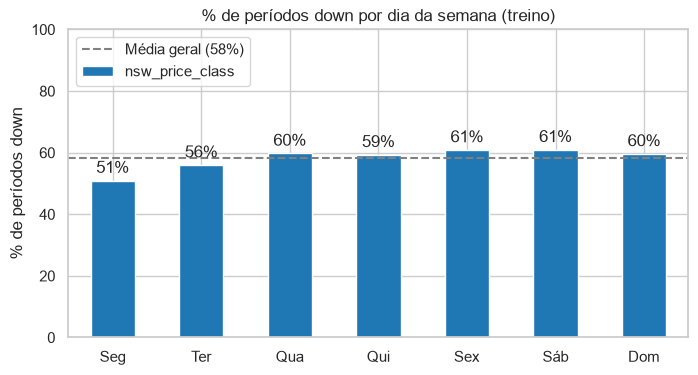

In [12]:
nomes_dias = {"day_1": "Seg", "day_2": "Ter", "day_3": "Qua", "day_4": "Qui",
              "day_5": "Sex", "day_6": "Sáb", "day_7": "Dom"}

taxa_down_por_dia = y_train.groupby(train["day"]).mean().rename(index=nomes_dias) * 100

ax = taxa_down_por_dia.plot.bar(figsize=(8, 4), color="tab:blue", rot=0)
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=3)
ax.axhline(y_train.mean() * 100, color="0.5", linestyle="--",
           label=f"Média geral ({y_train.mean():.0%})")
ax.set_ylim(0, 100)
ax.set_title("% de períodos down por dia da semana (treino)")
ax.set_xlabel("")
ax.set_ylabel("% de períodos down")
ax.legend(loc="upper left")
plt.show()

**Resposta:** sim, mas o efeito é bem menor que o do horário: a proporção de `down` varia só entre 51% e 61% ao longo da semana (no horário, ia de 33% a 95%). O dia que mais se destaca é a **segunda-feira**, com a menor proporção (51%).

**Por que a segunda-feira é diferente:** lembrando que `down` compara o preço atual com a média das **últimas 24 horas**. Na segunda, essas 24 horas são o domingo, um dia de consumo baixo e energia barata, porque o comércio, os escritórios e boa parte das indústrias estão fechados. Quando a semana de trabalho começa, a demanda sobe e o preço fica acima da média barata do domingo com mais frequência, o que gera mais períodos `up`.

**O efeito contrário aparece no sábado (61%):** ele é comparado com a sexta, um dia útil de energia mais cara. Com menos atividade no fim de semana, o preço do sábado tende a ficar abaixo dessa média.

**Implicação:** o dia da semana ajuda a prever a classe, principalmente para separar a segunda-feira. Como `day` é uma categoria sem ordem numérica real, será transformado em one-hot na Etapa 3.

### Pergunta 5: como as variáveis numéricas se relacionam entre si e com o alvo?

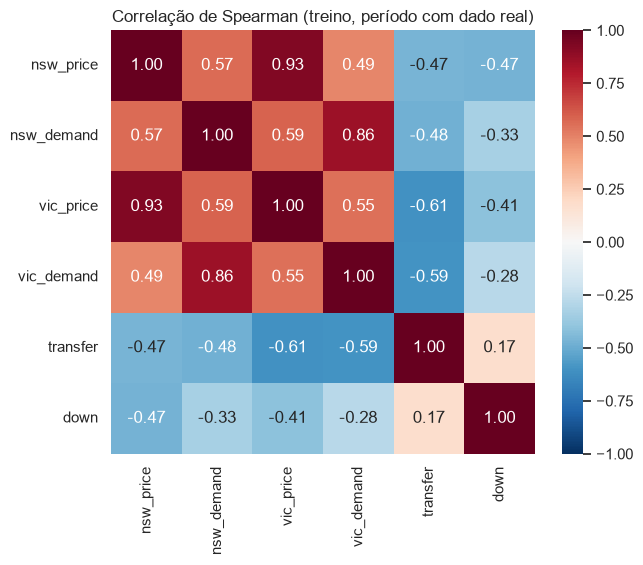

Preço NSW x preço VIC - Spearman: 0.93 | Pearson: 0.37


In [13]:
# Só o período com dado real de Victoria: os valores fixos distorceriam as correlações
dados_reais = periodo_completo[NUM_COLS].copy()
dados_reais["down"] = y_train[periodo_completo.index]
dados_reais.columns = [coluna.replace("_normalized", "") for coluna in dados_reais.columns]

correlacoes = dados_reais.corr(method="spearman")

plt.figure(figsize=(7, 5.5))
sns.heatmap(correlacoes, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Correlação de Spearman (treino, período com dado real)")
plt.show()

pearson_precos = dados_reais["nsw_price"].corr(dados_reais["vic_price"])
print(f"Preço NSW x preço VIC - Spearman: {correlacoes.loc['nsw_price', 'vic_price']:.2f}"
      f" | Pearson: {pearson_precos:.2f}")

**Resposta:**

**Entre as variáveis:**
- **Preços de NSW e Victoria andam juntos (0,93).** Os dois estados são vizinhos e ligados por linhas de transmissão: quando a energia fica cara em um, a tendência é ficar cara no outro também.
- **As demandas dos dois estados também (0,86).** Os dois têm rotinas parecidas (horário de trabalho, de sono, fim de semana) e clima semelhante, então o consumo sobe e desce nos mesmos momentos.
- **A transferência entre os estados tem relação negativa com a demanda e o preço de Victoria (≈ -0,6).** Quando o consumo e o preço sobem, a quantidade transferida diminui, o que sugere que, com a demanda alta, cada estado precisa da própria energia e sobra menos para enviar ao vizinho.

**Com o alvo (`down`):**
- As correlações são **negativas e moderadas**: quanto maiores o preço e a demanda, menor a chance de `down`. Isso confirma a Pergunta 2.
- A mais forte é o preço de NSW (-0,47), seguida do preço de Victoria (-0,41). Nenhuma passa de 0,5 em valor absoluto, ou seja, **nenhuma variável sozinha define a classe**.

**Por que Spearman:** a correlação de Pearson é muito afetada pelos picos de preço vistos na Pergunta 1. Para os preços dos dois estados, ela dá só 0,37, enquanto a Spearman, que compara a ordem dos valores, mostra a relação forte que de fato existe (0,93).

**Implicação:** as variáveis de Victoria trazem informação útil, o que reforça a decisão da Etapa 1 de mantê-las (com o indicador `vic_sem_dado`). Alguns pares são muito correlacionados entre si (os preços dos dois estados e as demandas dos dois estados), ou seja, carregam informação parecida. Esse ponto será retomado na escolha e na comparação dos modelos.

### Pergunta 6: a classe tende a se repetir de um período para o seguinte?

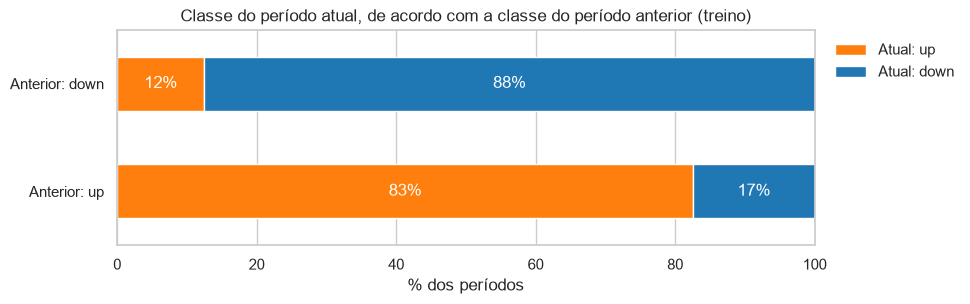

Repetir a classe anterior acertaria 85.5% dos períodos
Duração de uma sequência da mesma classe: mediana de 3 períodos, média de 6.9 e máximo de 82


In [14]:
classe_anterior = y_train.shift(1)        # a classe da meia hora anterior, na mesma linha

transicoes = pd.crosstab(classe_anterior, y_train, normalize="index") * 100
transicoes.index   = ["Anterior: up", "Anterior: down"]
transicoes.columns = ["Atual: up", "Atual: down"]

ax = transicoes.plot.barh(stacked=True, figsize=(9, 2.8), color=["tab:orange", "tab:blue"])
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f%%", label_type="center", color="white")
ax.set_xlim(0, 100)
ax.set_title("Classe do período atual, de acordo com a classe do período anterior (treino)")
ax.set_xlabel("% dos períodos")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.show()

acerto_repetindo = (y_train == classe_anterior).iloc[1:].mean()
print(f"Repetir a classe anterior acertaria {acerto_repetindo:.1%} dos períodos")

id_sequencia = (y_train != y_train.shift(1)).cumsum()
tamanho_sequencias = y_train.groupby(id_sequencia).size()
print(f"Duração de uma sequência da mesma classe: mediana de {tamanho_sequencias.median():.0f} períodos, "
      f"média de {tamanho_sequencias.mean():.1f} e máximo de {tamanho_sequencias.max()}")

**Resposta:** sim, a classe é muito persistente. Depois de um período `down`, 88% dos seguintes também são `down`; depois de um `up`, 83% continuam `up`. Uma sequência da mesma classe dura tipicamente 3 períodos (1h30), mas algumas se estendem por muito mais tempo (até 82 períodos, cerca de 41 horas).

**Por que isso acontece:**
- **O preço muda de forma gradual:** ele acompanha a rotina de consumo, que sobe e desce aos poucos ao longo do dia. De uma meia hora para a outra, o preço costuma mudar pouco.
- **A média de comparação muda muito devagar:** a média das últimas 24h é calculada sobre 48 períodos, e cada nova meia hora troca só 1 deles. Ela funciona como uma linha quase fixa.
- Assim, o preço fica do mesmo lado da média por um tempo e só "cruza" a linha em alguns momentos do dia, como quando a demanda sobe de manhã ou cai à noite (Pergunta 3).

**Implicação:** simplesmente repetir a classe anterior acertaria 85,5% dos períodos. Porém, a classe anterior é calculada pela mesma regra do alvo (o preço comparado com a média das últimas 24h, que será analisada na Pergunta 7). Por isso ela **não será usada como variável** nos modelos.

### Pergunta 7: o alvo pode ser explicado pelo preço em relação às últimas 24 horas?

Média dos últimos 24 períodos (12.0 h): a regra acerta 85.78%
Média dos últimos 47 períodos (23.5 h): a regra acerta 99.43%
Média dos últimos 48 períodos (24.0 h): a regra acerta 100.00%
Média dos últimos 49 períodos (24.5 h): a regra acerta 99.44%
Média dos últimos 96 períodos (48.0 h): a regra acerta 90.35%


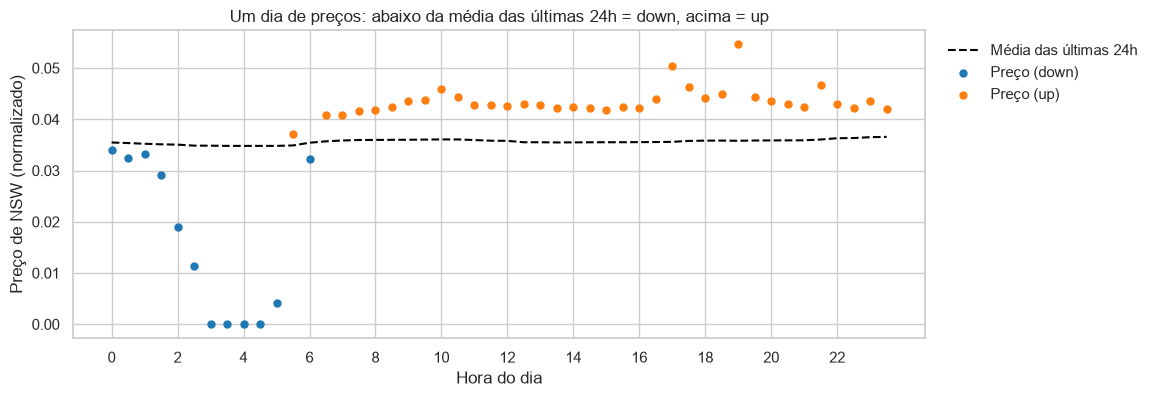

In [15]:
# Pergunta 7: o alvo pode ser explicado pelo preço em relação às últimas 24 horas?
preco_nsw = train["nsw_price_normalized"]

for janela in [24, 47, 48, 49, 96]:
    media_anterior = preco_nsw.shift(1).rolling(janela).mean()   # média dos períodos ANTERIORES
    regra = (preco_nsw < media_anterior).astype(int)              # 1 = abaixo da média = down
    acerto = (regra == y_train).iloc[janela:].mean()
    print(f"Média dos últimos {janela:>2} períodos ({janela / 2:>4.1f} h): a regra acerta {acerto:.2%}")

# Visualização da regra em um dia
inicio = 20160                                   # meia-noite de uma terça, no período com dado real
um_dia = pd.DataFrame({
    "hora":      (train["period_index"] - 1) / 2,
    "preco":     preco_nsw,
    "media_24h": preco_nsw.shift(1).rolling(48).mean(),
    "classe":    train[TARGET],
}).iloc[inicio : inicio + 48]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(um_dia["hora"], um_dia["media_24h"], color="black", linestyle="--", label="Média das últimas 24h")
for classe, cor in [("down", "tab:blue"), ("up", "tab:orange")]:
    pontos = um_dia[um_dia["classe"] == classe]
    ax.scatter(pontos["hora"], pontos["preco"], color=cor, s=25, zorder=3, label=f"Preço ({classe})")
ax.set_xticks(range(0, 24, 2))
ax.set_title("Um dia de preços: abaixo da média das últimas 24h = down, acima = up")
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Preço de NSW (normalizado)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.show()

**Resposta:** sim, e de forma exata. O alvo (`nsw_price_class`, a coluna que os modelos precisam prever) não é uma informação independente: ele foi **calculado** a partir do próprio preço. A regra "o preço atual de NSW está abaixo da média dos 48 períodos anteriores (24 horas) → `down`; acima → `up`" reproduz **100%** das classes do treino. Com janelas vizinhas (47 ou 49 períodos) o acerto já cai para cerca de 99,4%, e com 12h ou 48h fica entre 85% e 91%, o que mostra que é exatamente essa a fórmula usada para criar a coluna. Isso é coerente com a descrição oficial da base (classe definida pela mudança do preço em relação à média móvel das últimas 24 horas).

O gráfico de um dia mostra isso: de madrugada, o preço fica abaixo da média das últimas 24h e todos os pontos são `down`; quando o consumo sobe pela manhã, o preço passa a linha e os pontos viram `up`.

Isso também explica as perguntas anteriores:
- **Horário (Pergunta 3):** a madrugada quase sempre fica abaixo da média do dia, então é quase toda `down`.
- **Segunda-feira (Pergunta 4):** a média de comparação é a do domingo barato.
- **Persistência (Pergunta 6):** a média de 24h muda devagar, então o preço fica do mesmo lado dela por um tempo.

**Decisão:** se os modelos recebessem variáveis que permitem refazer essa conta (média móvel do preço, preços dos períodos anteriores ou a classe anterior), qualquer algoritmo chegaria perto de 100% e a comparação entre modelos não mediria nada. Por isso, mantendo o alvo definido no trabalho, **essas variáveis não serão criadas**. Os modelos aprendem apenas com as informações do próprio período: preços, demandas, transferência, horário e dia da semana.

**Consequência esperada:** o desempenho dos modelos ficará bem abaixo de 100%, porque eles não têm acesso à média das últimas 24h, a informação que define o alvo.

### Pergunta 8: a proporção de down muda ao longo do tempo?

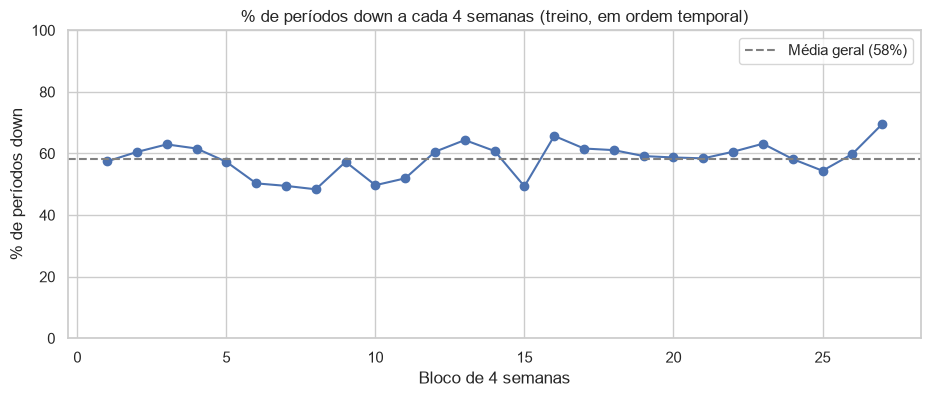

Menor: 48% | Maior: 70% | Último bloco antes do teste: 70%


In [16]:
periodos_em_4_semanas = 48 * 28
bloco = np.arange(len(train)) // periodos_em_4_semanas    # número do bloco de 4 semanas de cada linha
taxa_down_por_bloco = y_train.groupby(bloco).mean() * 100

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(taxa_down_por_bloco.index + 1, taxa_down_por_bloco, marker="o")
ax.axhline(y_train.mean() * 100, color="0.5", linestyle="--",
           label=f"Média geral ({y_train.mean():.0%})")
ax.set_ylim(0, 100)
ax.set_title("% de períodos down a cada 4 semanas (treino, em ordem temporal)")
ax.set_xlabel("Bloco de 4 semanas")
ax.set_ylabel("% de períodos down")
ax.legend()
plt.show()

print(f"Menor: {taxa_down_por_bloco.min():.0f}% | Maior: {taxa_down_por_bloco.max():.0f}% "
      f"| Último bloco antes do teste: {taxa_down_por_bloco.iloc[-1]:.0f}%")

**Resposta:** sim. A proporção de `down` não é constante: a cada 4 semanas ela varia entre 48% e 70%. Há um trecho com valores perto de 50% (blocos 6 a 11) e outros acima de 60%, e o último bloco antes do teste é o mais alto (70%).

**Por que isso acontece:** o mercado de energia muda ao longo do tempo. Fatores como as estações do ano (que alteram o consumo com aquecimento e ar-condicionado), a quantidade de energia disponível e mudanças nas regras do mercado fazem os preços se comportarem de forma diferente de um mês para outro. Como a classe compara o preço com a média do último dia, essas mudanças alteram com que frequência o preço fica abaixo dela.

**Implicações:**
- **Validação temporal:** como os dados mudam com o tempo, os modelos serão validados sempre treinando no passado e testando no futuro (`TimeSeriesSplit`), como acontecerá na prática.
- **O teste pode ter outra proporção:** o desempenho medido no treino pode não se repetir exatamente no teste, que vem depois.
- **Mudança de padrão (concept drift):** um modelo treinado uma única vez pode ficar desatualizado. Essa é a motivação do bônus com aprendizado online (`river`), em que o modelo continua aprendendo a cada novo dado.

### Síntese da EDA

**Principais achados:**

| # | Pergunta | Achado | Uso nas próximas etapas |
|---|---|---|---|
| 1 | Distribuição do preço | Concentrado em valores baixos, com picos raros e muito altos (cauda longa) | Padronização dentro do Pipeline; mediana como medida típica |
| 2 | Preço e demanda por classe | Menores nos períodos `down`, mas com grande sobreposição entre as classes | Nenhuma variável separa as classes sozinha: os modelos precisam combinar várias |
| 3 | Horário do dia | Relação mais forte da base: até 95% `down` de madrugada e 33% no fim da manhã | `period_index` em seno e cosseno |
| 4 | Dia da semana | Efeito menor (51% a 61%); a segunda-feira se destaca por ser comparada com o domingo | `day` em one-hot |
| 5 | Correlações | Preços e demandas dos dois estados andam juntos; com o alvo, relações negativas e moderadas | Manter as variáveis de Victoria com o indicador `vic_sem_dado` |
| 6 | Persistência da classe | A classe se repete em ~85% dos períodos seguidos | A classe anterior não será usada como variável |
| 7 | Origem do alvo | O alvo é exatamente "preço abaixo da média das últimas 24h" | Não criar variáveis que refaçam essa conta |
| 8 | Proporção ao longo do tempo | Varia entre 48% e 70% a cada 4 semanas | Validação temporal (`TimeSeriesSplit`) e bônus com aprendizado online |

**Conclusão:** o horário do dia, a demanda e o preço são as informações mais ligadas à classe, e o padrão muda ao longo do tempo. Como o alvo depende da média das últimas 24h, que os modelos não vão receber, espera-se um desempenho bom, mas longe de 100%.

**Limitações da análise:**
- A EDA usou apenas o treino; o teste pode ter outro comportamento, como sugere a Pergunta 8.
- As análises com as variáveis de Victoria usaram só o período com dado real, cerca de metade do treino.
- As variáveis estão normalizadas, então não é possível interpretar valores em unidades reais (R$, MW).
- As explicações sobre rotina de consumo, estações e mercado são hipóteses: os dados mostram os padrões, mas não as causas.
- Correlação não significa causa, e a correlação de Spearman só capta relações que sobem ou descem juntas (monotônicas).

## Etapa 3: Preparação das variáveis

Esta etapa transforma as colunas originais nas variáveis de entrada (X) dos modelos, usando as decisões das Etapas 1 e 2:

| Variável | O que é | Por quê |
|---|---|---|
| Preço, demanda e transferência (5 colunas) | Colunas originais, já normalizadas entre 0 e 1 | Ligadas à classe (Pergunta 2 e Pergunta 5) |
| `vic_sem_dado` | 1 quando as colunas de Victoria têm valores fixos | Avisa o modelo de que esses valores não são reais (Etapa 1) |
| `hora_sin` e `hora_cos` | Horário do dia transformado em um círculo | O horário tem o efeito mais forte, e 23h30 fica perto de 0h (Pergunta 3) |
| `dia_Seg` … `dia_Dom` | Uma coluna 0/1 para cada dia (one-hot) | Os dias são categorias, não uma escala (Pergunta 4) |

**Ficam de fora:**
- `date_normalized`: a escala não é confiável (Etapa 1).
- Preços anteriores, média móvel do preço e classe anterior: refariam a conta que gera o alvo (Pergunta 7).

A mesma função é aplicada ao treino e ao teste, então os dois ficam com as mesmas colunas, na mesma ordem.

In [17]:
def preparar_variaveis(dados):
    X = dados[NUM_COLS + ["vic_sem_dado"]].copy()

    angulo = 2 * np.pi * (dados["period_index"] - 1) / 48
    X["hora_sin"] = np.sin(angulo)
    X["hora_cos"] = np.cos(angulo)

    dia_semana = dados["day"].map(nomes_dias).astype(pd.CategoricalDtype(list(nomes_dias.values())))
    dias = pd.get_dummies(dia_semana, prefix="dia", dtype=int)

    return pd.concat([X, dias], axis=1)

X_train = preparar_variaveis(train)
X_test = preparar_variaveis(test)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Mesmas colunas no treino e no teste:", list(X_train.columns) == list(X_test.columns))
print(list(X_train.columns))

relogio = X_train.groupby(train["period_index"])[["hora_sin", "hora_cos"]].first()

def distancia(periodo_a, periodo_b):
    return np.linalg.norm(relogio.loc[periodo_a] - relogio.loc[periodo_b])

print(f"23h30 -> 0h00  | diferença no period_index: {48 - 1:>2} | distância no seno/cosseno: {distancia(48, 1):.2f}")
print(f" 0h00 -> 0h30  | diferença no period_index: {2 - 1:>2} | distância no seno/cosseno: {distancia(1, 2):.2f}")
print(f" 0h00 -> 12h00 | diferença no period_index: {25 - 1:>2} | distância no seno/cosseno: {distancia(1, 25):.2f}")

X_train: (36240, 15) | X_test: (9072, 15)
Mesmas colunas no treino e no teste: True
['nsw_price_normalized', 'nsw_demand_normalized', 'vic_price_normalized', 'vic_demand_normalized', 'transfer_normalized', 'vic_sem_dado', 'hora_sin', 'hora_cos', 'dia_Seg', 'dia_Ter', 'dia_Qua', 'dia_Qui', 'dia_Sex', 'dia_Sáb', 'dia_Dom']
23h30 -> 0h00  | diferença no period_index: 47 | distância no seno/cosseno: 0.13
 0h00 -> 0h30  | diferença no period_index:  1 | distância no seno/cosseno: 0.13
 0h00 -> 12h00 | diferença no period_index: 24 | distância no seno/cosseno: 2.00


**Resultado:** o treino ficou com 36.240 linhas e o teste com 9.072, os dois com as mesmas 15 variáveis.

**Horário em círculo:** no `period_index`, 23h30 (48) e 0h (1) parecem estar nos extremos opostos, com diferença de 47, mas na prática são horários vizinhos, com consumo e preço parecidos. Com seno e cosseno, a distância entre eles (0,13) é igual à de 0h para 0h30, e o meio-dia fica do lado oposto (2,00). Assim os modelos enxergam o dia como ele é: um ciclo que recomeça à meia-noite.

**Dia da semana em one-hot:** se `day` entrasse como número (1 a 7), o modelo entenderia que domingo (7) é "maior" que segunda (1) e que a distância entre eles é grande, mas os dois são dias vizinhos e nenhum é maior que outro. Com uma coluna 0/1 para cada dia, cada dia tem seu próprio efeito.

**Padronização:** as variáveis ainda não estão na mesma escala (por exemplo, o seno e o cosseno vão de -1 a 1 e os preços se concentram perto de 0,05). A padronização (`StandardScaler`) será feita dentro do `Pipeline` de cada modelo na Etapa 4. Assim, em cada rodada da validação, a média e o desvio são calculados apenas com os dados de treino daquela rodada, sem usar informação do período de validação.

## Etapa 4: Comparação dos modelos

**Modelos comparados:**
- **Baseline:** sempre responde a classe mais frequente (`down`). Não aprende nada; serve de referência mínima.
- **Regressão Logística:** combina as variáveis com pesos e traça uma fronteira reta entre as classes. Simples e fácil de interpretar.
- **KNN:** classifica cada período olhando os 15 períodos mais parecidos do treino.
- **Random Forest:** conjunto de 200 árvores de decisão; capta relações não lineares e combinações entre variáveis.
- **SVM (kernel RBF):** busca a fronteira com maior margem entre as classes, podendo ser curva.
- **MLP:** rede neural com duas camadas ocultas (32 e 16 neurônios).

Os modelos sensíveis à escala (Regressão Logística, KNN, SVM e MLP) recebem o `StandardScaler` dentro de um `Pipeline`. O Random Forest não precisa de padronização, porque cada árvore apenas compara valores com limites.

**Validação:** `TimeSeriesSplit` com 5 rodadas. Em cada rodada, o modelo treina com o passado e é avaliado no período seguinte, nunca o contrário, como aconteceria no uso real. A validação aleatória (`StratifiedKFold`) misturaria futuro e passado e daria resultados otimistas, já que a classe persiste entre períodos seguidos (Pergunta 6).

**Métricas** (classe positiva = `down`):
- **F1 de `down`:** equilíbrio entre acertar os `down` previstos (precisão) e encontrar os `down` reais (recall).
- **PR-AUC:** qualidade da ordenação dos períodos do mais para o menos provável de ser `down`, sem depender de um limiar. O Baseline fica na proporção de `down` (~0,58), que é o piso.
- **Acurácia:** apenas complementar, porque a classe `down` é a maioria.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

modelos = {
    "Baseline": DummyClassifier(strategy="most_frequent"),

    "Regressão Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=15))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE
    ),

    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", random_state=RANDOM_STATE))
    ]),

    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(hidden_layer_sizes=(32, 16), early_stopping=True,
                              max_iter=500, random_state=RANDOM_STATE))
    ]),
}

In [19]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate

cv = TimeSeriesSplit(n_splits=5)

for numero, (indices_treino, indices_validacao) in enumerate(cv.split(X_train), start=1):
    print(f"Rodada {numero}: treina com {len(indices_treino):>5} períodos | "
          f"valida nos {len(indices_validacao)} seguintes | "
          f"down na validação: {y_train.iloc[indices_validacao].mean():.1%}")

metricas = {
    "f1_down": "f1",
    "pr_auc": "average_precision",
    "acuracia": "accuracy",
}

resultados_cv = []

for nome, modelo in modelos.items():
    scores = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas)

    resultados_cv.append({
        "modelo": nome,
        "f1_down": scores["test_f1_down"].mean(),
        "pr_auc": scores["test_pr_auc"].mean(),
        "acuracia": scores["test_acuracia"].mean(),
        "tempo_treino (s)": scores["fit_time"].mean(),
    })

df_cv = pd.DataFrame(resultados_cv).sort_values("pr_auc", ascending=False).round(3)
df_cv

Rodada 1: treina com  6040 períodos | valida nos 6040 seguintes | down na validação: 51.9%
Rodada 2: treina com 12080 períodos | valida nos 6040 seguintes | down na validação: 56.6%
Rodada 3: treina com 18120 períodos | valida nos 6040 seguintes | down na validação: 60.1%
Rodada 4: treina com 24160 períodos | valida nos 6040 seguintes | down na validação: 59.5%
Rodada 5: treina com 30200 períodos | valida nos 6040 seguintes | down na validação: 60.8%


,modelo,f1_down,pr_auc,acuracia,tempo_treino (s)
1,Regressão Logística,0.811,0.865,0.740,0.066
5,MLP,0.804,0.855,0.737,3.737
3,Random Forest,0.777,0.826,0.708,2.128
4,SVM (RBF),0.795,0.802,0.729,13.229
2,KNN,0.791,0.793,0.723,0.073
0,Baseline,0.732,0.578,0.578,0.013


In [20]:
comparacao = []

for nome in ["Regressão Logística", "MLP", "KNN", "Random Forest"]:
    scores = cross_validate(modelos[nome], X_train, y_train, cv=cv,
                            scoring="average_precision", return_train_score=True)
    comparacao.append({
        "modelo": nome,
        "pr_auc_treino": scores["train_score"].mean(),
        "pr_auc_validacao": scores["test_score"].mean(),
    })

df_comparacao = pd.DataFrame(comparacao)
df_comparacao["queda"] = df_comparacao["pr_auc_treino"] - df_comparacao["pr_auc_validacao"]
df_comparacao.round(3)

,modelo,pr_auc_treino,pr_auc_validacao,queda
0,Regressão Logística,0.913,0.865,0.048
1,MLP,0.936,0.855,0.081
2,KNN,0.949,0.793,0.156
3,Random Forest,1.000,0.826,0.174


**Resultado:** todos os modelos superaram o Baseline. A **Regressão Logística** ficou em primeiro em todas as métricas (PR-AUC 0,865 e F1 0,811), seguida de perto pelo MLP. O Random Forest, o SVM e o KNN ficaram abaixo.

**Ganho sobre o Baseline:** o F1 parece próximo (0,81 contra 0,73), porque o Baseline responde `down` sempre e assim encontra todos os `down` reais. A PR-AUC mostra a diferença real: 0,865 contra 0,578. O Baseline não sabe ordenar os períodos, e a Regressão Logística sabe quais têm mais chance de ser `down`.

**Por que o modelo mais simples foi o melhor:**

1. **O padrão principal é simples.** O alvo compara o preço atual com um nível de referência (a média das últimas 24h). Na maior parte do tempo, isso se resume a uma regra direta: preço e demanda baixos, principalmente de madrugada, indicam `down`; preço e demanda altos, no horário comercial, indicam `up` (Perguntas 2, 3 e 5). A Regressão Logística aprende exatamente esse tipo de regra: soma as variáveis com pesos e decide de um lado ou do outro de uma fronteira reta. Os modelos mais complexos não tinham um padrão mais complicado para descobrir.

2. **Os modelos complexos "decoraram" o treino.** A tabela acima compara o desempenho nos dados de treino com o desempenho nos dados novos. O Random Forest acertou 100% da ordenação no treino, mas caiu para 0,83 na validação. O KNN também teve uma queda grande. A Regressão Logística quase não caiu (de 0,91 para 0,87). É como um aluno que decora as respostas das provas antigas: vai muito bem nelas, mas erra quando a prova muda. Quem entendeu a regra geral se sai melhor na prova nova.

3. **A prova muda com o tempo.** O comportamento do mercado varia de um mês para outro (Pergunta 8), e a validação sempre testa num período futuro. Detalhes decorados do passado deixam de valer, e a regra geral continua funcionando.

4. **A informação que falta não foi dada aos modelos.** O alvo depende da média das últimas 24h (Pergunta 7). Essa média poderia ser calculada a partir das linhas anteriores, mas foi deixada de fora de propósito, para que os modelos não apenas refizessem a conta do alvo. Sem ela, parte dos casos parece ruído, e os modelos flexíveis acabam aprendendo esse ruído como se fosse padrão.

**Custo:** o SVM foi de longe o mais lento para treinar e não trouxe ganho de desempenho. A Regressão Logística, além de ser a melhor, está entre as mais rápidas. Os tempos exatos variam conforme a máquina, mas essa ordem se mantém. Num uso real, com dados novos chegando a cada 30 minutos, isso pesa a favor da Regressão Logística.

### Experimento: treino inteiro com indicador × só o período completo

Na Etapa 1, cerca de 48% do treino tinha valores fixos nas colunas de Victoria. A decisão foi manter essas linhas com o indicador `vic_sem_dado`, e este experimento testa se ela foi acertada. Os modelos são treinados de duas formas:

- **Treino inteiro + indicador:** todas as linhas, com `vic_sem_dado` avisando quais têm valores fixos.
- **Só período completo:** apenas as linhas com dados reais de Victoria (menos dados, mas todos reais).

As duas formas são avaliadas no mesmo bloco de validação: a última rodada do `TimeSeriesSplit`, que fica inteira no período com dados reais, igual ao teste. O SVM ficou de fora por ser lento.

In [21]:
from sklearn.base import clone
from sklearn.metrics import f1_score, average_precision_score, precision_score, recall_score

indices_treino, indices_validacao = list(cv.split(X_train))[-1]
X_parte_treino, y_parte_treino = X_train.iloc[indices_treino], y_train.iloc[indices_treino]
X_validacao, y_validacao = X_train.iloc[indices_validacao], y_train.iloc[indices_validacao]

periodo_real = X_parte_treino["vic_sem_dado"] == 0
opcoes_treino = {
    "Treino inteiro + indicador": (X_parte_treino, y_parte_treino),
    "Só período completo": (X_parte_treino[periodo_real], y_parte_treino[periodo_real]),
}

for opcao, (X_opcao, y_opcao) in opcoes_treino.items():
    print(f"{opcao}: {len(X_opcao)} períodos de treino")

resultados_experimento = []

for nome in ["Regressão Logística", "MLP", "KNN", "Random Forest"]:
    for opcao, (X_opcao, y_opcao) in opcoes_treino.items():
        modelo = clone(modelos[nome]).fit(X_opcao, y_opcao)
        nota_down = modelo.predict_proba(X_validacao)[:, 1]
        resultados_experimento.append({
            "modelo": nome,
            "treino": opcao,
            "pr_auc": average_precision_score(y_validacao, nota_down),
        })

df_experimento = pd.DataFrame(resultados_experimento).pivot(index="modelo", columns="treino", values="pr_auc")
df_experimento["diferença"] = df_experimento["Treino inteiro + indicador"] - df_experimento["Só período completo"]
df_experimento.round(3)

Treino inteiro + indicador: 30200 períodos de treino
Só período completo: 12776 períodos de treino


treino,Só período completo,Treino inteiro + indicador,diferença
modelo,,,
KNN,0.770,0.765,-0.005
MLP,0.833,0.832,-0.000
Random Forest,0.822,0.821,-0.002
Regressão Logística,0.813,0.826,0.012


**Resultado:** as diferenças entre as duas formas de treino foram muito pequenas (no máximo 0,012 de PR-AUC). Para o KNN, o MLP e o Random Forest, a diferença ficou praticamente em zero. A Regressão Logística, o melhor modelo da comparação, foi a que mais ganhou com o treino inteiro (0,826 contra 0,813).

**Por que o indicador funcionou:** as linhas com valores fixos em Victoria não atrapalharam, porque o `vic_sem_dado` avisa o modelo para não confiar nessas colunas ali. Ao mesmo tempo, essas linhas continuam trazendo informação útil de NSW (preço, demanda, horário e dia), que estão corretos em todo o treino.

**Decisão:** manter o **treino inteiro com o indicador**, como definido na Etapa 1. Ele usa mais que o dobro de dados, não piorou nenhum modelo de forma relevante e melhorou o modelo principal.

**Limitação:** o experimento usou um único bloco de validação, então diferenças tão pequenas não provam que uma opção é melhor; elas mostram que as duas são equivalentes e que descartar metade dos dados não traria ganho.

## Etapa 5: Ajuste dos modelos

Na Etapa 4, os modelos usaram parâmetros iniciais. Agora cada um passa por uma busca pequena de hiperparâmetros com `GridSearchCV`, usando a mesma validação temporal (`TimeSeriesSplit`) e a PR-AUC como critério. O teste continua sem ser usado.

**O que é ajustado em cada modelo:**
- **Regressão Logística:** `C`, que controla a regularização. Quanto menor, mais o modelo é "segurado" e menos se ajusta aos detalhes do treino.
- **KNN:** o número de vizinhos. Com mais vizinhos, a decisão fica mais suave.
- **Random Forest:** a profundidade máxima das árvores (`max_depth`) e o mínimo de períodos em cada folha (`min_samples_leaf`). Os dois limitam o quanto cada árvore pode decorar.
- **MLP:** o tamanho da rede e o `alpha`, a regularização. Quanto maior o `alpha`, mais contida a rede.

O SVM ficou de fora: foi o mais lento e não teve vantagem na Etapa 4.

Depois, o modelo escolhido passa pelo ajuste do **limiar de decisão**, para melhorar o F1 de `down`.

In [22]:
from sklearn.model_selection import GridSearchCV

grades = {
    "Regressão Logística": {"logreg__C": [0.001, 0.01, 0.1, 1]},
    "KNN": {"knn__n_neighbors": [15, 51, 101, 201, 401]},
    "Random Forest": {"max_depth": [5, 10, None], "min_samples_leaf": [1, 20, 100]},
    "MLP": {"mlp__hidden_layer_sizes": [(8,), (16,), (32, 16)], "mlp__alpha": [0.0001, 1, 10]},
}

pr_auc_antes = df_cv.set_index("modelo")["pr_auc"]
modelos_ajustados = {}
resultados_busca = []

for nome, grade in grades.items():
    busca = GridSearchCV(modelos[nome], grade, cv=cv, scoring="average_precision", n_jobs=-1)
    busca.fit(X_train, y_train)
    modelos_ajustados[nome] = busca.best_estimator_

    resultados_busca.append({
        "modelo": nome,
        "pr_auc_antes": pr_auc_antes[nome],
        "pr_auc_depois": busca.best_score_,
        "melhores_parametros": busca.best_params_,
    })

df_busca = pd.DataFrame(resultados_busca).sort_values("pr_auc_depois", ascending=False).round(3)
df_busca

,modelo,pr_auc_antes,pr_auc_depois,melhores_parametros
3,MLP,0.855,0.869,"{'mlp__alpha': 10, 'mlp__hidden_layer_sizes': ..."
0,Regressão Logística,0.865,0.868,{'logreg__C': 0.01}
2,Random Forest,0.826,0.863,"{'max_depth': 10, 'min_samples_leaf': 20}"
1,KNN,0.793,0.831,{'knn__n_neighbors': 201}


**Resultado:** todos os modelos melhoraram, e em todos a melhor configuração foi a mais contida:
- Regressão Logística: o menor `C` útil (0,01), ou seja, mais regularização;
- KNN: 201 vizinhos em vez de 15, uma decisão mais suave;
- Random Forest: árvores limitadas (profundidade 10 e pelo menos 20 períodos por folha), com o maior ganho (de 0,826 para 0,863);
- MLP: o maior `alpha` testado (10), ou seja, a rede mais regularizada.

Isso confirma a explicação da Etapa 4: o que prejudicava os modelos era decorar detalhes do passado. Quando eles são impedidos de decorar, todos se aproximam de 0,86–0,87.

**Escolha do modelo: Regressão Logística.** O MLP ficou numericamente à frente, mas a diferença (0,869 contra 0,868) é muito menor do que a variação da PR-AUC entre as rodadas da validação; na prática, é um empate. Entre dois modelos empatados, a Regressão Logística é a melhor escolha:
- é mais simples: menos chance de se comportar de forma inesperada em dados novos;
- é muito mais rápida para treinar;
- é interpretável: cada variável tem um peso que mostra se aumenta ou diminui a chance de `down`.

In [23]:
modelo_escolhido = modelos_ajustados["Regressão Logística"]

notas_validacao, classes_validacao = [], []

for indices_treino, indices_validacao in cv.split(X_train):
    modelo = clone(modelo_escolhido).fit(X_train.iloc[indices_treino], y_train.iloc[indices_treino])
    notas_validacao.append(modelo.predict_proba(X_train.iloc[indices_validacao])[:, 1])
    classes_validacao.append(y_train.iloc[indices_validacao])

resultados_limiar = []

for limiar in np.arange(0.30, 0.71, 0.05):
    previsoes = [(notas >= limiar).astype(int) for notas in notas_validacao]
    f1_rodadas = [f1_score(reais, prev) for reais, prev in zip(classes_validacao, previsoes)]

    resultados_limiar.append({
        "limiar": round(limiar, 2),
        "precisao": np.mean([precision_score(reais, prev) for reais, prev in zip(classes_validacao, previsoes)]),
        "recall": np.mean([recall_score(reais, prev) for reais, prev in zip(classes_validacao, previsoes)]),
        "f1_down": np.mean(f1_rodadas),
        "f1_ultima_rodada": f1_rodadas[-1],
    })

pd.DataFrame(resultados_limiar).round(3)

,limiar,precisao,recall,f1_down,f1_ultima_rodada
0,0.30,0.645,0.988,0.780,0.782
1,0.35,0.657,0.983,0.787,0.783
2,0.40,0.669,0.979,0.794,0.785
3,0.45,0.681,0.972,0.800,0.786
4,0.50,0.697,0.961,0.807,0.786
5,0.55,0.717,0.947,0.815,0.785
6,0.60,0.740,0.922,0.819,0.784
7,0.65,0.763,0.894,0.819,0.773
8,0.70,0.783,0.847,0.807,0.744


**O problema com o limiar padrão (0,5):** o modelo responde `down` com muita facilidade. Ele encontra 96% dos `down` reais (recall), mas só 70% das vezes em que diz `down` está certo (precisão). Isso acontece porque `down` é a classe mais frequente, então as notas do modelo já tendem para esse lado.

**O que o aumento do limiar faz:** exige mais certeza para responder `down`. O modelo erra menos ao dizer `down` (a precisão sobe) e deixa escapar alguns `down` reais (o recall cai). O F1 equilibra os dois e chega ao máximo entre 0,60 e 0,65 (0,819, contra 0,807 no limiar 0,5).

**Limiar escolhido: 0,60.** Os limiares 0,60 e 0,65 empatam no F1 médio, mas na rodada mais recente, a mais parecida com o teste, o 0,65 já piora (0,773 contra 0,784). O 0,60 melhora o F1 médio sem perder desempenho no período mais recente.

O limiar foi escolhido apenas com a validação do treino; o teste continua intocado até a Etapa 6.

In [24]:
limiar_escolhido = 0.60

## Etapa 6: Avaliação no conjunto de teste

Esta é a única vez que o teste é usado. Todas as escolhas (modelo, hiperparâmetros e limiar) já foram feitas com a validação do treino e **não serão alteradas** a partir deste resultado; caso contrário, o teste deixaria de medir o desempenho em dados realmente novos.

O teste contém os 9.072 períodos finais da base (cerca de 27 semanas), todas com dados reais de Victoria.

1. Primeiro, todos os modelos ajustados são avaliados no teste, para registro.
2. Depois, o modelo escolhido (Regressão Logística, limiar 0,60) é analisado em detalhe.

In [25]:
from sklearn.metrics import accuracy_score

modelos_finais = {"Baseline": modelos["Baseline"], **modelos_ajustados}

resultados_teste = []

for nome, modelo in modelos_finais.items():
    modelo.fit(X_train, y_train)
    nota_down = modelo.predict_proba(X_test)[:, 1]
    previsao = modelo.predict(X_test)

    resultados_teste.append({
        "modelo": nome,
        "f1_down": f1_score(y_test, previsao),
        "pr_auc": average_precision_score(y_test, nota_down),
        "acuracia": accuracy_score(y_test, previsao),
    })

df_teste = pd.DataFrame(resultados_teste).sort_values("pr_auc", ascending=False).round(3)
df_teste

,modelo,f1_down,pr_auc,acuracia
3,Random Forest,0.722,0.898,0.746
1,Regressão Logística,0.677,0.889,0.716
4,MLP,0.742,0.883,0.754
2,KNN,0.788,0.870,0.764
0,Baseline,0.709,0.549,0.549


**Resultado:** na PR-AUC, todos os modelos ficaram muito acima do Baseline (0,87 a 0,90 contra 0,549) e até acima do que tinham na validação. Ou seja, eles continuam sabendo ordenar os períodos do mais para o menos provável de ser `down`.

O F1 e a acurácia, que dependem do limiar de 0,5, caíram bastante, e a ordem dos modelos mudou em relação à validação. A Regressão Logística, que vinha em primeiro, ficou abaixo do Baseline no F1. Essa mudança de comportamento entre validação e teste é analisada nas próximas células.

**A escolha do modelo não muda:** escolher o modelo com o melhor resultado no teste (o KNN no F1, por exemplo) seria usar o teste para tomar decisões. O teste deixaria de ser uma medida honesta do desempenho em dados novos.

F1 de down: 0.574
Precisão:   0.924
Recall:     0.417
PR-AUC:     0.889
Acurácia:   0.661
Previstos como down: 24.7% | down reais no teste: 54.9%


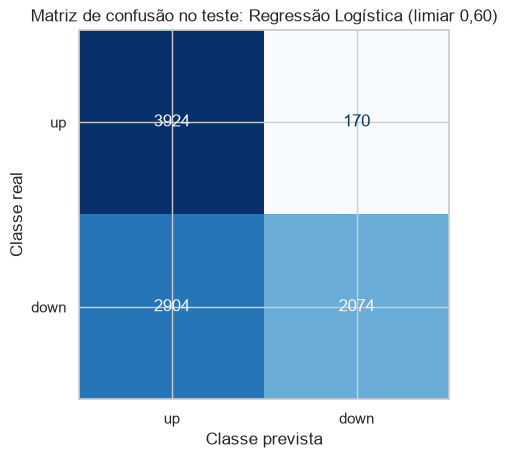

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

nota_down_teste = modelo_escolhido.predict_proba(X_test)[:, 1]
previsao_teste = (nota_down_teste >= limiar_escolhido).astype(int)

print(f"F1 de down: {f1_score(y_test, previsao_teste):.3f}")
print(f"Precisão:   {precision_score(y_test, previsao_teste):.3f}")
print(f"Recall:     {recall_score(y_test, previsao_teste):.3f}")
print(f"PR-AUC:     {average_precision_score(y_test, nota_down_teste):.3f}")
print(f"Acurácia:   {accuracy_score(y_test, previsao_teste):.3f}")
print(f"Previstos como down: {previsao_teste.mean():.1%} | down reais no teste: {y_test.mean():.1%}")

ConfusionMatrixDisplay.from_predictions(y_test, previsao_teste, display_labels=["up", "down"],
                                        cmap="Blues", colorbar=False)
plt.title("Matriz de confusão no teste: Regressão Logística (limiar 0,60)")
plt.xlabel("Classe prevista"); plt.ylabel("Classe real")
plt.show()

**Resultado:** quando o modelo diz `down`, ele quase sempre acerta (precisão de 92%), mas encontrou só 42% dos `down` reais (recall). Ele previu `down` em apenas 25% dos períodos, enquanto o teste tem 55%. O erro principal está na matriz: 2.904 períodos `down` foram classificados como `up`.

**Comportamento oposto ao da validação:** na validação, o modelo errava por excesso de `down` (recall de 96%), e por isso o limiar foi aumentado para 0,60. No teste, ele erra por falta de `down`, e o limiar mais alto piorou esse erro. A escolha do limiar estava correta para os dados disponíveis, mas o teste se comportou de forma diferente. A próxima célula investiga o motivo.

In [27]:
preco = "nsw_price_normalized"

blocos = {
    "Treino inteiro": (train, y_train),
    "Fim do treino (última rodada)": (train.iloc[-6040:], y_train.iloc[-6040:]),
    "Teste": (test, y_test),
}

comparacao_preco = pd.DataFrame({
    nome: {
        "preço mediano": dados[preco].median(),
        "mediano nos down": dados[preco][classes == 1].median(),
        "mediano nos up": dados[preco][classes == 0].median(),
        "% down": classes.mean() * 100,
    }
    for nome, (dados, classes) in blocos.items()
}).T.round(3)

comparacao_preco

,preço mediano,mediano nos down,mediano nos up,% down
Treino inteiro,0.047,0.042,0.069,58.215
Fim do treino (última rodada),0.031,0.029,0.035,60.828
Teste,0.059,0.045,0.085,54.872


**A causa: o nível de preço mudou.** No fim do treino, os preços estavam muito baixos (mediana 0,031). No teste, praticamente dobraram (0,059). Mesmo os períodos `down` do teste (mediana 0,045) custam mais que os períodos `up` típicos do fim do treino (0,035).

**Por que isso derruba o F1:** o modelo aprendeu principalmente com o preço: quanto mais caro, maior a chance de `up`. Mas ele aprendeu isso em **valores absolutos**. Já o alvo é **relativo**: `down` significa abaixo da média das últimas 24h, e essa média sobe junto quando o mercado inteiro fica mais caro. Como a média de 24h não foi dada aos modelos (Pergunta 7), o modelo usa um nível de preço que valia no passado. No teste, ele vê preços "caros" e responde `up`, mesmo quando o período está abaixo da média recente.

**Por que a PR-AUC continuou alta:** dentro do teste, os períodos mais baratos continuam sendo os mais prováveis de `down`. A ordem que o modelo faz continua certa; o que mudou foi o ponto de corte.

**Conclusão:** o modelo aprendeu um padrão útil (ordena bem os períodos), mas o corte que transforma a nota em `down`/`up` não se manteve com a mudança do nível de preço. Esse é um exemplo real de *concept drift*, e a próxima etapa testa uma solução: um modelo que **se atualiza a cada novo período** (aprendizado online com `river`).

## Etapa 7 — Bônus: aprendizado online com river

Na Etapa 6, o modelo escolhido piorou no teste porque **o nível de preço do mercado subiu**. Ele foi treinado uma vez só e ficou "congelado": continuou achando caro um preço que, no teste, já era normal.

O **aprendizado online** ataca exatamente esse problema. Em vez de treinar uma vez e parar, o modelo aprende um período por vez, o tempo todo:

1. chega um novo período de 30 minutos → o modelo **prevê** se será `up` ou `down`;
2. o período termina e a classe real fica conhecida → o modelo **aprende** com ela e ajusta um pouco os pesos;
3. passa para o próximo período.

Esse esquema se chama **testar e depois treinar** (*test-then-train*). Cada previsão é feita **antes** de o modelo ver a resposta daquele período, então não há vazamento. O esquema também é realista: a classe de um período só depende do preço dele e das 24h anteriores, e por isso ela é conhecida assim que o período acaba.

Para a comparação ser justa:
- o modelo online usa a **mesma família** do escolhido (Regressão Logística) e as **mesmas 15 variáveis**;
- ele usa as **configurações padrão** do river, sem nenhum ajuste, para que o teste não seja usado em nenhuma escolha;
- ele percorre primeiro o treino inteiro e depois segue aprendendo durante o teste.

In [28]:
from river import linear_model, preprocessing, stream

modelo_online = preprocessing.StandardScaler() | linear_model.LogisticRegression()

def prever_e_aprender(modelo, X, y):
    notas = []
    for periodo, classe_real in stream.iter_frame(X, y):
        notas.append(modelo.predict_proba_one(periodo).get(True, 0.0))
        modelo.learn_one(periodo, bool(classe_real))
    return np.array(notas)

nota_online_treino = prever_e_aprender(modelo_online, X_train, y_train)
nota_online_teste = prever_e_aprender(modelo_online, X_test, y_test)

def resumir(nome, notas, limiar):
    previsao = (notas >= limiar).astype(int)
    return {
        "modelo": nome,
        "f1_down": f1_score(y_test, previsao),
        "precisao": precision_score(y_test, previsao),
        "recall": recall_score(y_test, previsao),
        "pr_auc": average_precision_score(y_test, notas),
        "acuracia": accuracy_score(y_test, previsao),
        "proporcao_prevista_down": previsao.mean(),
    }

print(f"Online no treino (cada período avaliado antes de aprender): F1 {f1_score(y_train, nota_online_treino >= 0.5):.3f}")
print(f"Proporção real de down no teste: {y_test.mean():.3f}")

comparacao_online = pd.DataFrame([
    resumir("Fixa (limiar 0,60, escolhido)", nota_down_teste, limiar_escolhido),
    resumir("Fixa (limiar 0,5)", nota_down_teste, 0.5),
    resumir("Online com river (limiar 0,5)", nota_online_teste, 0.5),
]).set_index("modelo").round(3)
comparacao_online

Online no treino (cada período avaliado antes de aprender): F1 0.866
Proporção real de down no teste: 0.549


,f1_down,precisao,recall,pr_auc,acuracia,proporcao_prevista_down
modelo,,,,,,
"Fixa (limiar 0,60, escolhido)",0.574,0.924,0.417,0.889,0.661,0.247
"Fixa (limiar 0,5)",0.677,0.903,0.541,0.889,0.716,0.329
"Online com river (limiar 0,5)",0.873,0.856,0.892,0.937,0.858,0.572


### Resultado: o modelo online acompanhou a mudança do mercado

O modelo online foi muito melhor no teste:

- **F1 de `down`:** 0,873, contra 0,574 do modelo fixo escolhido (e 0,677 do fixo com limiar 0,5).
- **Acurácia:** 0,858, contra 0,661.
- **PR-AUC:** 0,937, contra 0,889. O online também ordenou melhor os períodos.

O ponto mais importante é a **proporção prevista de `down`**. O modelo fixo previu `down` em só 24,7% dos períodos, quando o real era 54,9%, porque continuava achando caros os preços que tinham virado normais. O online previu 57,2%, bem perto do real. Foi isso que fez o recall subir de 0,417 para 0,892.

**Por que ele se adapta?** A cada período, o modelo online ajusta um pouco os pesos na direção do erro que acabou de cometer. Os períodos recentes acabam pesando mais que os antigos, e o modelo "esquece" aos poucos os níveis de preço do passado. Quando o mercado ficou mais caro, ele errou nos primeiros períodos, corrigiu os pesos e passou a usar o novo nível de preço como referência.

**O resultado não é sorte do teste.** No próprio treino, avaliando cada período antes de aprender, o online já chegava a F1 0,866, acima do 0,811 que a Regressão Logística fixa teve na validação cruzada. O preço do treino também muda com o tempo (Etapa 6), e o online lida melhor com isso ali também.

**Comparação justa?** O online tem uma vantagem real: ele recebe a classe correta de cada período depois que o período termina, e o fixo nunca recebe. Essa é justamente a proposta do aprendizado online e é viável na prática, porque a classe é conhecida assim que o período acaba. Nenhuma configuração do river foi ajustada, então o teste não foi usado para escolher nada.

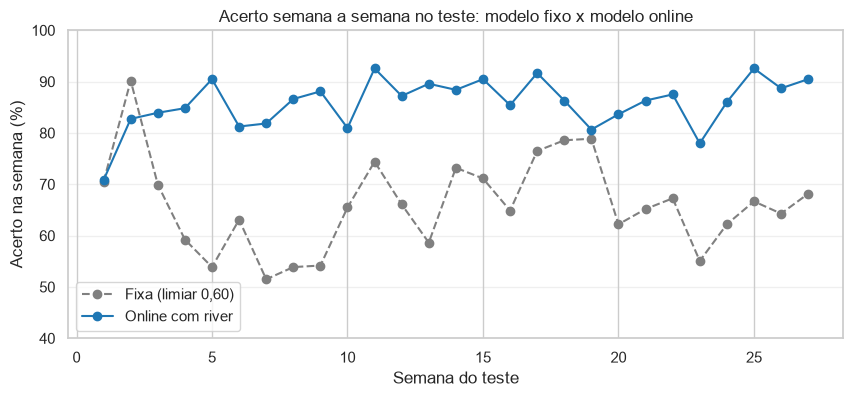

In [29]:
periodos_por_semana = 48 * 7
semana = np.arange(len(y_test)) // periodos_por_semana + 1

acertos = pd.DataFrame({
    "Fixa (limiar 0,60)": previsao_teste == y_test.values,
    "Online com river": (nota_online_teste >= 0.5) == y_test.values,
}).groupby(semana).mean() * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(acertos.index, acertos["Fixa (limiar 0,60)"], color="gray", linestyle="--", marker="o", label="Fixa (limiar 0,60)")
ax.plot(acertos.index, acertos["Online com river"], color="tab:blue", marker="o", label="Online com river")
ax.set_title("Acerto semana a semana no teste: modelo fixo x modelo online")
ax.set_xlabel("Semana do teste")
ax.set_ylabel("Acerto na semana (%)")
ax.set_ylim(40, 100)
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.show()

### O que o gráfico mostra

- **Semana 1:** os dois empatam (cerca de 71%). Os dois começam o teste sabendo a mesma coisa, porque ambos aprenderam com o treino inteiro.
- **Semanas 3 a 9:** o preço sobe, e o modelo fixo despenca para a faixa de 51% a 70%, perto de chutar. O online se ajusta logo e se mantém entre 81% e 90%.
- **Restante do teste:** o fixo oscila entre 55% e 79%, conforme o preço chega mais perto ou mais longe do que ele conhecia. O online fica quase sempre acima de 80%.
- O online acertou mais que o fixo em **25 das 27 semanas**. Ele empatou na primeira e perdeu só na segunda, quando o preço ainda estava parecido com o do fim do treino.

**Conclusão do bônus:** neste problema, o que limita o modelo não é o algoritmo, mas o fato de o mercado mudar com o tempo. Um modelo simples que **continua aprendendo** supera o melhor modelo treinado uma vez só. Na prática, para prever preço de energia, vale mais atualizar o modelo continuamente do que buscar um algoritmo mais complexo.